# 고객 이탈 예측 — 로지스틱 회귀 · SVM · 결정 트리 분류

수업 중 작성한 필기 `고객이탈예측.ipynb` 를 **실행 가능하도록 정리 · 개선한 노트**입니다.
(데이터: Kaggle Telco Customer Churn · 배포 자료 `Telco 고객 이탈 데이터 설명서.pdf`)

- 원본에서 고친 부분은 **📝 고친 부분**, 필기에 남긴 질문의 답은 **💬 필기 질문** 으로 따로 적어 두었습니다.
- 그림 · **애니메이션(GIF)** 은 [`images/`](./images/) 폴더에 미리 만들어 두었고, 아래 코드를 실행하면 같은 그림이 다시 그려집니다.
- 수업의 EDA 그래프는 `plotly` 라 GitHub 미리보기에는 안 보입니다 → 같은 내용을 `matplotlib` 그림으로도 저장했습니다.

| 단계 | 내용 |
|---|---|
| 1 | 데이터 불러오기 · 전처리 (`TotalCharges` 공백 11건) |
| 2 | EDA — 이탈 비율 · 계약 형태 · 가입 기간 · 요금 |
| 3 | 인코딩 (라벨 · 원-핫) → 학습용 / 평가용 분리 |
| 4 | 로지스틱 회귀 → **SVM (스케일링 전 / 후)** → 결정 트리 (깊이) |
| 5 | 평가 지표 (정확도 · 정밀도 · 재현율 · F1) · 임계값 · 모델 비교 |

In [1]:
# 경고 메시지 숨기기
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import plotly.express as px
import matplotlib.pyplot as plt
import platform, os

# 그래프 한글 폰트 설정 (운영체제별)
if platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif platform.system() == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'
else:
    plt.rcParams['font.family'] = 'Noto Sans CJK JP'   # Linux / Colab 은 나눔·Noto 폰트 설치 필요
plt.rcParams['axes.unicode_minus'] = False

# 그림 저장 폴더
os.makedirs('./images', exist_ok=True)
SAVE_GIF = True     # False 로 바꾸면 GIF 를 다시 만들지 않음 (시간 절약)

## 1. 데이터 불러오기

In [2]:
# 파일 경로 설정 -> 노트북과 같은 폴더의 CSV (상대경로)
file_path = './Telco-Customer-Churn.csv'

# DataFrame 생성
df = pd.read_csv(file_path)

print(f'데이터 크기(행, 열): {df.shape}')
display(df.head())

데이터 크기(행, 열): (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


| 구분 | 컬럼 |
|---|---|
| 고객 인구통계 | `customerID`(학습 제외), `gender`, `SeniorCitizen`(1 = 65세 이상), `Partner`, `Dependents` |
| 가입 서비스 | `PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies` |
| 계약 · 결제 | `tenure`(가입 개월 수), `Contract`, `PaperlessBilling`, `PaymentMethod`, `MonthlyCharges`(월 요금), `TotalCharges`(총 누적 요금) |
| **정답** | `Churn` — Yes(이탈) / No(유지) |

## 2. 데이터 전처리

In [3]:
# 기본 정보(행 · 열 수, 결측치, 자료형) -> info()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

👉 `TotalCharges` 는 요금(숫자)인데 자료형이 **문자열(str)** → 숫자로 바꿀 수 없는 값이 섞여 있다.

In [4]:
# 문제점: TotalCharges 에 숫자로 바꿀 수 없는 공백 문자열(' ') 포함
space_index = df.query("TotalCharges == ' '").index
print(f'공백 행 {len(space_index)}개: {space_index.tolist()}')

# 공백 행 확인 -> 모두 tenure(가입 기간) = 0 -> 아직 첫 요금이 청구되지 않은 신규 고객
display(df.loc[space_index, ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']])

공백 행 11개: [488, 753, 936, 1082, 1340, 3331, 3826, 4380, 5218, 6670, 6754]


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [5]:
# 1단계: 문자열 -> 숫자 -> pd.to_numeric(), 변환 못 하는 값(' ')은 NaN 으로 (errors='coerce')
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print(f"TotalCharges 자료형: {df['TotalCharges'].dtype}, 결측치: {df['TotalCharges'].isna().sum()}개")

# 2단계: 결측치 행 제거 -> dropna(), 인덱스 0부터 다시 (ignore_index=True)
df1 = df.dropna(ignore_index=True)
print(f'제거 전 {df.shape} -> 제거 후 {df1.shape}')

TotalCharges 자료형: float64, 결측치: 11개
제거 전 (7043, 21) -> 제거 후 (7032, 21)


> 💡 11건(0.16%)뿐이라 제거해도 영향이 작다. `tenure = 0` 이므로 제거 대신 `fillna(0)` 으로 채워도 된다.

## 3. EDA — 어떤 고객이 떠나는가

In [6]:
# 정답(Churn) 항목별 비율 -> value_counts(normalize=True) -> reset_index()
df_churn_ratio = df1['Churn'].value_counts(normalize=True).reset_index()
display(df_churn_ratio)

fig1 = px.pie(df_churn_ratio, names='Churn', values='proportion', title='고객 이탈 여부 비중', hole=0.3)
fig1.show()

,Churn,proportion
0,No,0.734215
1,Yes,0.265785


👉 유지 **73.4%** : 이탈 **26.6%** → **불균형 데이터**. 전부 "유지"라고 찍어도 정확도가 **0.734** 나온다.
이 값이 오늘 모델들이 넘어야 할 **기준선(baseline)** 이다.

In [7]:
# 계약 형태(Contract) x 이탈(Churn) 고객 수 -> groupby + size() -> reset_index()
df_contract_churn_count = df1.groupby(by=['Contract', 'Churn']).size().reset_index(name='Count')
display(df_contract_churn_count)

fig2 = px.bar(df_contract_churn_count, x='Contract', y='Count', color='Churn',
              barmode='group', text_auto=True, title='계약 형태별 이탈 / 유지 고객 수')
fig2.show()

,Contract,Churn,Count
0,Month-to-month,No,2220
1,Month-to-month,Yes,1655
2,One year,No,1306
3,One year,Yes,166
4,Two year,No,1637
5,Two year,Yes,48


In [8]:
# 수치형 3개(tenure, MonthlyCharges, TotalCharges) x 이탈 -> 히스토그램, 같은 모양이라 반복문으로
hist_titles = {
    'tenure': '가입 기간(개월)에 따른 이탈 분포',
    'MonthlyCharges': '월 사용 요금과 고객 이탈의 관계',
    'TotalCharges': '총 누적 요금과 고객 이탈의 관계',
}
for col, title in hist_titles.items():
    fig = px.histogram(df1, x=col, color='Churn', barmode='group', title=title)
    fig.update_traces(marker_line_color='black', marker_line_width=1)   # 막대 경계선
    fig.show()

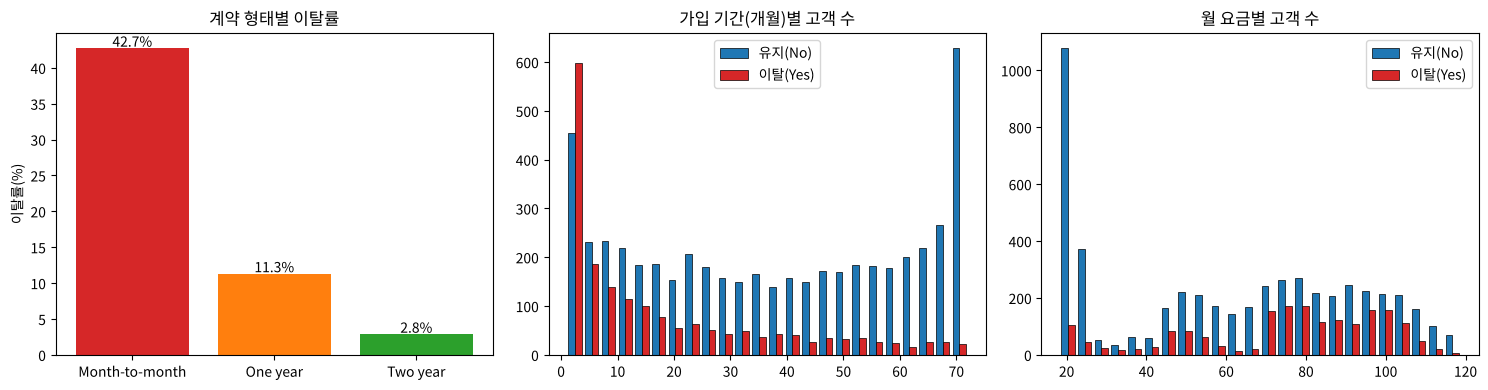

Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: Churn, dtype: float64


In [9]:
# 같은 내용을 matplotlib 그림 한 장으로 저장 (GitHub 미리보기용)
rate = df1.groupby('Contract')['Churn'].apply(lambda s: (s == 'Yes').mean() * 100)
stay, churn = df1[df1['Churn'] == 'No'], df1[df1['Churn'] == 'Yes']

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
bars = ax[0].bar(rate.index, rate.values, color=['#d62728', '#ff7f0e', '#2ca02c'])
ax[0].bar_label(bars, fmt='%.1f%%')
ax[0].set_title('계약 형태별 이탈률'); ax[0].set_ylabel('이탈률(%)')
for i, (col, t) in enumerate([('tenure', '가입 기간(개월)'), ('MonthlyCharges', '월 요금')], start=1):
    ax[i].hist([stay[col], churn[col]], bins=24, label=['유지(No)', '이탈(Yes)'],
               color=['#1f77b4', '#d62728'], edgecolor='black', linewidth=0.5)
    ax[i].set_title(f'{t}별 고객 수'); ax[i].legend()
plt.tight_layout()
plt.savefig('./images/00_eda.png', dpi=110)
plt.show()
print(rate.round(1))

| 관찰 | |
|---|---|
| 계약 형태 | **월 단위 42.7%** ≫ 1년 11.3% ≫ 2년 2.8% |
| `tenure` | 가입 **초기(0~10개월)** 이탈이 몰려 있고, 오래될수록 거의 안 떠난다 |
| `MonthlyCharges` | **70~105** 의 비싼 요금 구간에서 이탈이 많다 |
| `TotalCharges` | 누적 요금이 낮을수록(= 가입 기간이 짧을수록) 이탈이 많다 |

> 💬 **필기 질문 — 다중공선성**: `TotalCharges ≈ tenure × MonthlyCharges` 라 세 컬럼이 서로 강하게 얽혀 있다(상관계수 `tenure`–`TotalCharges` ≈ 0.83).
> 같은 정보가 겹치면 **선형 모델의 계수 해석이 불안정**해진다(부호가 뒤집히기도 함). 예측 성능만 보면 큰 문제는 아니지만, 계수로 "원인"을 말하려면 하나를 빼고 비교해 본다.

In [10]:
print(df1[['tenure', 'MonthlyCharges', 'TotalCharges']].corr().round(2))

                tenure  MonthlyCharges  TotalCharges
tenure            1.00            0.25          0.83
MonthlyCharges    0.25            1.00          0.65
TotalCharges      0.83            0.65          1.00


## 4. 인코딩

In [11]:
# 고유 번호(customerID) 삭제 -> 고객마다 다른 값이라 예측에 쓸모없음
df2 = df1.drop(columns='customerID')

# 정답 라벨 인코딩 -> map(): 'No' -> 0, 'Yes' -> 1
df2['Churn'] = df2['Churn'].map({'No': 0, 'Yes': 1})
display(df2.head())

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


> 💬 **필기 질문 — `replace` vs `map`**: 둘 다 값을 바꾸지만, `map` 은 딕셔너리에 **없는 값을 NaN** 으로 만들고 `replace` 는 **그대로 둔다**.
> 정답처럼 Yes/No 두 개만 있어야 하는 컬럼은 `map` 을 쓰면 오타 · 이상값이 NaN 으로 드러나 오히려 안전하다.

In [12]:
# 원-핫 인코딩: 문자열(범주형) 컬럼 이름 -> select_dtypes() -> columns -> tolist()
## pandas 3.x 는 문자열 자료형이 'str' -> 버전에 상관없이 'object', 'string' 함께 지정
categorical_cols_list = df2.select_dtypes(include=['object', 'string']).columns.tolist()
print(f'범주형 컬럼 {len(categorical_cols_list)}개: {categorical_cols_list}')
print(f'수치형 컬럼: {df2.select_dtypes(include="number").columns.tolist()}')

# pd.get_dummies() -> 범주형 컬럼만 0 / 1 컬럼으로 펼치기
df_onehot = pd.get_dummies(df2, columns=categorical_cols_list, dtype=int)
print(f'인코딩 전 {df2.shape} -> 인코딩 후 {df_onehot.shape}')

범주형 컬럼 15개: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
수치형 컬럼: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']
인코딩 전 (7032, 20) -> 인코딩 후 (7032, 46)


> 💬 **필기 질문 — "float64 2개, int64 로 구별해야 할 것 같은데 모르겠다"**: 원-핫 인코딩 대상은 **문자열 컬럼만**이다.
> `MonthlyCharges` · `TotalCharges`(float64)와 `SeniorCitizen` · `tenure`(int64)는 이미 숫자라 **그대로 두면 된다** — `select_dtypes(include=['object', 'string'])` 가 문자열만 골라 주므로 따로 구별할 필요가 없다.
> (`SeniorCitizen` 은 이미 0/1 이라 원-핫이 필요 없다.)

## 5. 학습용 데이터와 평가용 데이터 생성

In [13]:
from sklearn.model_selection import train_test_split

X_data = df_onehot.drop(columns=['Churn'])   # 문제
y_data = df_onehot['Churn']                  # 정답

# 8:2 분리, random_state: 재현성, stratify: 정답 비율 유지
X_train, X_test, y_train, y_test = train_test_split(
    X_data, y_data, test_size=0.2, random_state=0, stratify=y_data)

print(f'X_train {X_train.shape}, X_test {X_test.shape}')

# stratify 효과 -> 전체 · 학습용 · 평가용 정답 비율이 같다
display(pd.DataFrame({'전체': y_data.value_counts(normalize=True),
                      '학습용': y_train.value_counts(normalize=True),
                      '평가용': y_test.value_counts(normalize=True)}).round(4))

X_train (5625, 45), X_test (1407, 45)


,전체,학습용,평가용
Churn,,,
0,0.7342,0.7342,0.7342
1,0.2658,0.2658,0.2658


## 6. 평가 함수 — 정확도만 보면 안 되는 이유
불균형 데이터라 **"이탈 고객을 몇 명이나 잡았나"(재현율)** 를 같이 본다.

| 지표 | 의미 (이탈 = 1 기준) |
|---|---|
| 정확도 | 전체 중 맞힌 비율 |
| 정밀도 | "이탈"이라고 예측한 고객 중 진짜 이탈 비율 |
| **재현율** | 진짜 이탈 고객 중 모델이 잡아낸 비율 ← 이탈 방어 마케팅에서 중요 |
| F1 | 정밀도와 재현율의 조화 평균 |

In [14]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

results = {}   # 모델별 성능을 모아 마지막에 비교

def evaluate(name, y_pred, model=None, X_tr=None):
    """정확도 · 정밀도 · 재현율 · F1 + 혼동 행렬 출력, results 에 저장"""
    row = {'정확도': accuracy_score(y_test, y_pred),
           '정밀도': precision_score(y_test, y_pred, zero_division=0),
           '재현율': recall_score(y_test, y_pred),
           'F1': f1_score(y_test, y_pred)}
    if model is not None:
        row['학습용 정확도'] = model.score(X_tr, y_train)
    results[name] = row
    print(f'[{name}] ' + ' · '.join(f'{k} {v:.4f}' for k, v in row.items()))
    display(pd.DataFrame(confusion_matrix(y_test, y_pred),
                         index=['실제 유지(0)', '실제 이탈(1)'], columns=['예측 유지(0)', '예측 이탈(1)']))

# 기준선: 전부 '유지(0)' 로 예측
evaluate('Baseline (전부 유지)', np.zeros(len(y_test), dtype=int))

[Baseline (전부 유지)] 정확도 0.7342 · 정밀도 0.0000 · 재현율 0.0000 · F1 0.0000


,예측 유지(0),예측 이탈(1)
실제 유지(0),1033,0
실제 이탈(1),374,0


## 7. 로지스틱 회귀 (LogisticRegression)

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning

# 모델 생성 -> 학습 (원본처럼 스케일링 없이)
lr_raw = LogisticRegression()
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter('always')
    lr_raw.fit(X_train, y_train)
print(f'반복 횟수: {lr_raw.n_iter_[0]} / max_iter=100, 수렴 경고: {any(issubclass(x.category, ConvergenceWarning) for x in w)}')

# 예측 -> 평가
evaluate('LogisticRegression (스케일링 X)', lr_raw.predict(X_test), lr_raw, X_train)

반복 횟수: 100 / max_iter=100, 수렴 경고: True


[LogisticRegression (스케일링 X)] 정확도 0.8067 · 정밀도 0.6645 · 재현율 0.5508 · F1 0.6023 · 학습용 정확도 0.8053


,예측 유지(0),예측 이탈(1)
실제 유지(0),929,104
실제 이탈(1),168,206


> 📝 **고친 부분** — 맨 위의 `warnings.filterwarnings('ignore')` 때문에 안 보였지만, 원본 로지스틱 회귀는 **`ConvergenceWarning`(수렴 실패)** 이 나고 있었다.
> `max_iter=100` 번 안에 최적값을 못 찾고 멈춘 것. 값 범위가 큰 `TotalCharges`(18~8,685) 때문이다 → 아래 **스케일링**으로 해결.

## 8. SVM — 스케일링 전 / 후

필기의 질문 그대로: **"표준화가 아닌가? 아니다 표준화를 한다!"** → `scaler` 는 만들었지만 `fit_transform` 줄이 주석이라 **스케일링 없이** 학습했다. 결과부터 보자.

In [16]:
from sklearn.svm import SVC

# 원본 필기 그대로: 스케일링 없이
svc_raw = SVC()
svc_raw.fit(X_train, y_train)
pred_svc_raw = svc_raw.predict(X_test)
evaluate('SVC (스케일링 X)', pred_svc_raw, svc_raw, X_train)
print('예측값 종류:', np.unique(pred_svc_raw, return_counts=True))

[SVC (스케일링 X)] 정확도 0.7342 · 정밀도 0.0000 · 재현율 0.0000 · F1 0.0000 · 학습용 정확도 0.7342


,예측 유지(0),예측 이탈(1)
실제 유지(0),1033,0
실제 이탈(1),374,0


예측값 종류: (array([0]), array([1407]))


> 📝 **고친 부분** — 필기의 SVC 정확도 **0.7342** 는 기준선(전부 "유지")과 **똑같은 숫자**다. 실제로 예측값이 **전부 0** — 이탈 고객을 한 명도 못 잡았다.
>
> **왜?** SVM(`rbf` 커널)은 점 사이 **거리**로 판단한다. `TotalCharges` 는 수천 단위, 원-핫 컬럼은 0/1 이라 거리가 사실상 `TotalCharges` 하나로만 계산되고,
> 기본 `gamma='scale'` 에서 모든 점이 "멀리 떨어진" 상태가 되어 다수 클래스(유지)만 고르게 된다.

![스케일링 애니메이션](./images/anim_01_scaling.gif)

🎬 같은 고객 400명을 `tenure`(가로) · `TotalCharges`(세로) **같은 눈금**으로 그렸다. 스케일링 전에는 가로 폭이 72, 세로 폭이 8,600 이라 점들이 **세로 한 줄**로 붙는다 — 거리 계산에서 `tenure` 는 거의 무시된다. `StandardScaler` 로 두 축을 **평균 0 · 표준편차 1** 로 맞추면 비로소 두 특성이 같은 무게로 거리에 들어간다.

In [17]:
from sklearn.preprocessing import StandardScaler

# 학습용으로만 fit (평균 · 표준편차 계산) -> 평가용은 transform 만 (평가 데이터 정보 유출 방지)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# SVC 다시
svc = SVC(random_state=0)
svc.fit(X_train_scaled, y_train)
evaluate('SVC (스케일링 O)', svc.predict(X_test_scaled), svc, X_train_scaled)

# 로지스틱 회귀도 스케일링 데이터로 -> 수렴 경고 사라짐
lr = LogisticRegression(random_state=0)
lr.fit(X_train_scaled, y_train)
print(f'\n로지스틱 회귀 반복 횟수: {lr.n_iter_[0]} (수렴 O)')
evaluate('LogisticRegression (스케일링 O)', lr.predict(X_test_scaled), lr, X_train_scaled)

[SVC (스케일링 O)] 정확도 0.7974 · 정밀도 0.6692 · 재현율 0.4706 · F1 0.5526 · 학습용 정확도 0.8185


,예측 유지(0),예측 이탈(1)
실제 유지(0),946,87
실제 이탈(1),198,176



로지스틱 회귀 반복 횟수: 28 (수렴 O)
[LogisticRegression (스케일링 O)] 정확도 0.8081 · 정밀도 0.6677 · 재현율 0.5535 · F1 0.6053 · 학습용 정확도 0.8059


,예측 유지(0),예측 이탈(1)
실제 유지(0),930,103
실제 이탈(1),167,207


In [18]:
# 스케일링 애니메이션 (images/anim_01_scaling.gif)
from matplotlib.animation import FuncAnimation, PillowWriter

rng = np.random.RandomState(0)
idx = rng.choice(len(X_train), 400, replace=False)
raw = X_train[['tenure', 'TotalCharges']].values[idx].astype(float)
std = (raw - raw.mean(axis=0)) / raw.std(axis=0)
col = np.where(y_train.values[idx] == 1, '#d62728', '#1f77b4')

fig, ax = plt.subplots(figsize=(6.4, 5.2))
def draw(f, n=40):
    t = min(f / n, 1.0); t = t * t * (3 - 2 * t)            # 부드럽게 (smoothstep)
    pts = (1 - t) * raw + t * std
    half = (1 - t) * 4400 + t * 3.2                           # 가로 · 세로 같은 눈금으로 축소
    cx, cy = (1 - t) * np.array([36, 4300])
    ax.clear()
    ax.scatter(pts[:, 0], pts[:, 1], c=col, s=12, alpha=0.7)
    ax.set_xlim(cx - half, cx + half); ax.set_ylim(cy - half, cy + half); ax.set_aspect('equal')
    ax.set_xlabel('tenure'); ax.set_ylabel('TotalCharges')
    if t < 0.02:
        ax.set_title('스케일링 전 — 같은 눈금이면 tenure 폭(72)은 안 보인다')
    elif t > 0.98:
        ax.set_title('StandardScaler 후 — 두 축 모두 평균 0, 표준편차 1')
    else:
        ax.set_title(f'표준화 중… {t * 100:.0f}%')
    ax.text(0.02, 0.02, '● 유지  ', color='#1f77b4', transform=ax.transAxes)
    ax.text(0.16, 0.02, '● 이탈', color='#d62728', transform=ax.transAxes)

if SAVE_GIF:
    frames = [0] * 10 + list(range(41)) + [40] * 14
    FuncAnimation(fig, draw, frames=frames).save('./images/anim_01_scaling.gif', writer=PillowWriter(fps=10), dpi=80)
plt.close(fig)

### SVM 의 `C` — 마진을 얼마나 너그럽게?

![SVM C 애니메이션](./images/anim_02_svm_C.gif)

🎬 특성을 `tenure` · `MonthlyCharges` 2개만 써서(스케일링 후) `rbf` SVM 의 결정 경계를 그렸다. 검은 테두리 점이 **서포트 벡터**.
`C` 가 작으면 오분류를 많이 봐주는 **넓고 부드러운 경계**(서포트 벡터 많음), 커질수록 학습 데이터를 다 맞히려고 **구불구불한 경계**가 된다(과대적합 위험).

In [19]:
# SVM C 애니메이션 (images/anim_02_svm_C.gif) -> 특성 2개, 600명
from sklearn.preprocessing import StandardScaler as _SS
two = ['tenure', 'MonthlyCharges']
i2 = np.random.RandomState(1).choice(len(X_train), 600, replace=False)
X2 = _SS().fit_transform(X_train[two].values[i2]); y2 = y_train.values[i2]
gx, gy = np.meshgrid(np.linspace(-2, 2.2, 220), np.linspace(-2, 2.2, 220))
grid2 = np.c_[gx.ravel(), gy.ravel()]
Cs = np.logspace(-2, 3, 26)

fig, ax = plt.subplots(figsize=(6.4, 5.4))
def draw_c(k):
    m = SVC(C=Cs[k], random_state=0).fit(X2, y2)
    Z = m.decision_function(grid2).reshape(gx.shape)
    ax.clear()
    ax.contourf(gx, gy, Z > 0, levels=[-0.5, 0.5, 1.5], colors=['#cfe0f3', '#f6caca'], alpha=0.8)
    ax.contour(gx, gy, Z, levels=[-1, 0, 1], colors='k', linestyles=['--', '-', '--'], linewidths=[0.8, 1.6, 0.8])
    ax.scatter(X2[:, 0], X2[:, 1], c=np.where(y2 == 1, '#d62728', '#1f77b4'), s=10)
    sv = m.support_vectors_
    ax.scatter(sv[:, 0], sv[:, 1], s=28, facecolors='none', edgecolors='k', linewidths=0.5)
    ax.set_xlim(-2, 2.2); ax.set_ylim(-2, 2.2)
    ax.set_xlabel('tenure (표준화)'); ax.set_ylabel('MonthlyCharges (표준화)')
    ax.set_title(f'C = {Cs[k]:.2f} · 서포트 벡터 {len(sv)}개 · 학습 정확도 {m.score(X2, y2):.3f}')

if SAVE_GIF:
    frames = [0] * 4 + list(range(len(Cs))) + [len(Cs) - 1] * 6
    FuncAnimation(fig, draw_c, frames=frames).save('./images/anim_02_svm_C.gif', writer=PillowWriter(fps=4), dpi=75)
plt.close(fig)

## 9. 결정 트리 (DecisionTreeClassifier)

> 💬 **필기 질문 — 트리도 스케일링?** 트리는 "`tenure` ≤ 15.5 ?" 처럼 **한 컬럼씩 기준값으로 나누기**만 해서 값의 크기 · 단위에 영향을 받지 않는다 → **스케일링 불필요**.

In [20]:
from sklearn.tree import DecisionTreeClassifier

# 필기 그대로: 기본값 (깊이 제한 없음)
dt = DecisionTreeClassifier(random_state=0)
dt.fit(X_train, y_train)
print(f'트리 깊이 {dt.get_depth()}, 잎 노드 {dt.get_n_leaves()}개')
evaluate('DecisionTree (기본값)', dt.predict(X_test), dt, X_train)

트리 깊이 27, 잎 노드 1105개
[DecisionTree (기본값)] 정확도 0.7193 · 정밀도 0.4721 · 재현율 0.4759 · F1 0.4740 · 학습용 정확도 0.9977


,예측 유지(0),예측 이탈(1)
실제 유지(0),834,199
실제 이탈(1),196,178


> 📝 **고친 부분** — 필기의 트리 정확도 **0.7193** 은 **기준선(0.734)보다 낮다**. 학습용 정확도는 **0.998** — 깊이 27, 잎 1,105개로 학습 데이터를 **외웠다**(과대적합).
> → `max_depth` 를 바꿔 가며 평가용 성능이 가장 좋은 깊이를 찾는다.

![트리 깊이 애니메이션](./images/anim_03_tree_depth.gif)

🎬 왼쪽은 특성 2개(`tenure` · `MonthlyCharges`)로 학습한 트리의 결정 경계, 오른쪽은 **전체 특성**으로 학습한 트리의 깊이별 정확도다.
깊이가 깊어질수록 경계가 잘게 쪼개지고, 학습용 정확도(파랑)는 1 로 올라가지만 평가용(빨강)은 **깊이 3 근처에서 최고**를 찍고 내려간다.

In [21]:
# 깊이별 학습용 / 평가용 정확도 (전체 특성)
depths = list(range(1, 28))
tr_acc, te_acc = [], []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=0).fit(X_train, y_train)
    tr_acc.append(m.score(X_train, y_train)); te_acc.append(m.score(X_test, y_test))

best_d = depths[int(np.argmax(te_acc))]
print(f'평가용 정확도 최고: 깊이 {best_d} -> {max(te_acc):.4f}')
display(pd.DataFrame({'깊이': depths, '학습용': tr_acc, '평가용': te_acc}).round(4).iloc[[0, 1, 2, 3, 4, 5, 7, 9, 14, 26]])

평가용 정확도 최고: 깊이 3 -> 0.7946


,깊이,학습용,평가용
0,1,0.7342,0.7342
1,2,0.7600,0.7704
2,3,0.7899,0.7946
3,4,0.7970,0.7875
4,5,0.8069,0.7861
5,6,0.8091,0.7903
7,8,0.8357,0.7761
9,10,0.8748,0.7662
14,15,0.9643,0.7228
26,27,0.9977,0.7193


In [22]:
# 트리 깊이 애니메이션 (images/anim_03_tree_depth.gif)
Xr2 = X_train[two].values[i2].astype(float)
gx2, gy2 = np.meshgrid(np.linspace(0, 72, 200), np.linspace(18, 119, 200))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
def draw_d(k):
    d = depths[k]
    m = DecisionTreeClassifier(max_depth=d, random_state=0).fit(Xr2, y2)
    Z = m.predict(np.c_[gx2.ravel(), gy2.ravel()]).reshape(gx2.shape)
    a = ax[0]; a.clear()
    a.contourf(gx2, gy2, Z, levels=[-0.5, 0.5, 1.5], colors=['#cfe0f3', '#f6caca'])
    a.scatter(Xr2[:, 0], Xr2[:, 1], c=np.where(y2 == 1, '#d62728', '#1f77b4'), s=8)
    a.set_xlabel('tenure'); a.set_ylabel('MonthlyCharges')
    a.set_title(f'max_depth = {d} · 잎 {m.get_n_leaves()}개 (특성 2개)')
    b = ax[1]; b.clear()
    b.plot(depths[:k + 1], tr_acc[:k + 1], 'o-', color='#1f77b4', ms=3, label='학습용')
    b.plot(depths[:k + 1], te_acc[:k + 1], 'o-', color='#d62728', ms=3, label='평가용')
    b.axhline(0.7342, color='gray', ls=':', label='기준선 0.734')
    b.set_xlim(0, 28); b.set_ylim(0.70, 1.01); b.set_xlabel('max_depth'); b.set_ylabel('정확도')
    b.set_title(f'전체 특성 · 깊이 {d}: 학습 {tr_acc[k]:.3f} / 평가 {te_acc[k]:.3f}'); b.legend(loc='upper left')
    plt.tight_layout()

if SAVE_GIF:
    frames = list(range(len(depths))) + [len(depths) - 1] * 8
    FuncAnimation(fig, draw_d, frames=frames).save('./images/anim_03_tree_depth.gif', writer=PillowWriter(fps=3), dpi=72)
plt.close(fig)

In [23]:
# 깊이를 제한한 트리 -> 정확도(깊이 3) / 재현율 · F1 균형(깊이 5) 둘 다 확인
for d in [3, 5]:
    m = DecisionTreeClassifier(max_depth=d, random_state=0).fit(X_train, y_train)
    evaluate(f'DecisionTree (max_depth={d})', m.predict(X_test), m, X_train)

dt5 = DecisionTreeClassifier(max_depth=5, random_state=0).fit(X_train, y_train)
print('\n깊이 5 트리의 특성 중요도 Top 5')
print(pd.Series(dt5.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(5).round(3))

[DecisionTree (max_depth=3)] 정확도 0.7946 · 정밀도 0.7053 · 재현율 0.3904 · F1 0.5026 · 학습용 정확도 0.7899


,예측 유지(0),예측 이탈(1)
실제 유지(0),972,61
실제 이탈(1),228,146


[DecisionTree (max_depth=5)] 정확도 0.7861 · 정밀도 0.6130 · 재현율 0.5294 · F1 0.5681 · 학습용 정확도 0.8069


,예측 유지(0),예측 이탈(1)
실제 유지(0),908,125
실제 이탈(1),176,198



깊이 5 트리의 특성 중요도 Top 5
Contract_Month-to-month        0.509
tenure                         0.162
InternetService_Fiber optic    0.141
TotalCharges                   0.071
MonthlyCharges                 0.030
dtype: float64


👉 트리가 가장 중요하게 본 특성은 **월 단위 계약(0.51)**, 가입 기간, 광섬유 인터넷 — EDA 에서 본 것과 같다.

## 10. 임계값(threshold) — 재현율을 올리는 방법

`predict()` 는 **이탈 확률 ≥ 0.5** 이면 1 로 정한다. 이탈 방어가 목적이면 기준을 낮춰 **더 많은 고객을 '위험'으로 분류**할 수 있다.

![임계값 애니메이션](./images/anim_04_threshold.gif)

🎬 왼쪽은 로지스틱 회귀가 평가용 고객에게 준 **이탈 확률** 분포(파랑 = 실제 유지, 빨강 = 실제 이탈), 오른쪽은 임계값에 따른 지표다.
임계값을 0.5 → 0.3 으로 내리면 재현율이 **0.55 → 0.76** 으로 오르고 F1 도 **0.61 → 0.64** 로 좋아진다. 대신 정밀도(오탐 줄이기)는 떨어진다 — **무엇을 더 아끼는지**(놓친 이탈 고객 vs 쓸데없는 쿠폰 비용)에 따라 고른다.

In [24]:
proba = lr.predict_proba(X_test_scaled)[:, 1]     # 이탈(1)일 확률
ths = np.round(np.arange(0.05, 0.951, 0.025), 3)
curve = pd.DataFrame([{'임계값': t,
                       '정밀도': precision_score(y_test, (proba >= t).astype(int), zero_division=0),
                       '재현율': recall_score(y_test, (proba >= t).astype(int)),
                       'F1': f1_score(y_test, (proba >= t).astype(int))} for t in ths])
display(curve[curve['임계값'].isin([0.2, 0.3, 0.4, 0.5, 0.6])].round(4))

evaluate('LogisticRegression (임계값 0.3)', (proba >= 0.3).astype(int))

,임계값,정밀도,재현율,F1
6,0.2,0.4703,0.8690,0.6103
10,0.3,0.5511,0.7647,0.6405
14,0.4,0.5986,0.6658,0.6304
18,0.5,0.6677,0.5535,0.6053
22,0.6,0.7254,0.3743,0.4938


[LogisticRegression (임계값 0.3)] 정확도 0.7719 · 정밀도 0.5511 · 재현율 0.7647 · F1 0.6405


,예측 유지(0),예측 이탈(1)
실제 유지(0),800,233
실제 이탈(1),88,286


In [25]:
# 임계값 애니메이션 (images/anim_04_threshold.gif)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
bins = np.linspace(0, 1, 31)
def draw_t(k):
    t = ths[k]
    a = ax[0]; a.clear()
    a.hist(proba[y_test.values == 0], bins=bins, color='#1f77b4', alpha=0.6, label='실제 유지')
    a.hist(proba[y_test.values == 1], bins=bins, color='#d62728', alpha=0.6, label='실제 이탈')
    a.axvline(t, color='k', lw=2); a.axvspan(t, 1, color='orange', alpha=0.12)
    caught = ((proba >= t) & (y_test.values == 1)).sum(); flagged = (proba >= t).sum()
    a.set_title(f'임계값 {t:.2f} → "이탈" 예측 {flagged}명 중 진짜 {caught}명')
    a.set_xlabel('이탈 확률 (predict_proba)'); a.set_ylabel('고객 수'); a.legend()
    b = ax[1]; b.clear()
    for c, colr in [('정밀도', '#2ca02c'), ('재현율', '#d62728'), ('F1', '#9467bd')]:
        b.plot(curve['임계값'], curve[c], color=colr, label=c)
        b.plot(t, curve[c][k], 'o', color=colr)
    b.axvline(0.5, color='gray', ls=':'); b.axvline(t, color='k', lw=1)
    b.set_ylim(0, 1.02); b.set_xlabel('임계값'); b.legend(loc='lower left')
    r = curve.iloc[k]
    b.set_title(f'정밀도 {r["정밀도"]:.2f} · 재현율 {r["재현율"]:.2f} · F1 {r["F1"]:.2f}')
    plt.tight_layout()

if SAVE_GIF:
    k05 = int(np.argmin(abs(ths - 0.5)))
    frames = [k05] * 5 + list(range(k05, -1, -1)) + list(range(0, len(ths))) + list(range(len(ths) - 1, k05 - 1, -1)) + [k05] * 4
    FuncAnimation(fig, draw_t, frames=frames).save('./images/anim_04_threshold.gif', writer=PillowWriter(fps=8), dpi=72)
plt.close(fig)

## 11. 모델 비교

,정확도,정밀도,재현율,F1,학습용 정확도
Baseline (전부 유지),0.7342,0.0000,0.0000,0.0000,NaN
LogisticRegression (스케일링 X),0.8067,0.6645,0.5508,0.6023,0.8053
SVC (스케일링 X),0.7342,0.0000,0.0000,0.0000,0.7342
SVC (스케일링 O),0.7974,0.6692,0.4706,0.5526,0.8185
LogisticRegression (스케일링 O),0.8081,0.6677,0.5535,0.6053,0.8059
DecisionTree (기본값),0.7193,0.4721,0.4759,0.4740,0.9977
DecisionTree (max_depth=3),0.7946,0.7053,0.3904,0.5026,0.7899
DecisionTree (max_depth=5),0.7861,0.6130,0.5294,0.5681,0.8069
LogisticRegression (임계값 0.3),0.7719,0.5511,0.7647,0.6405,NaN


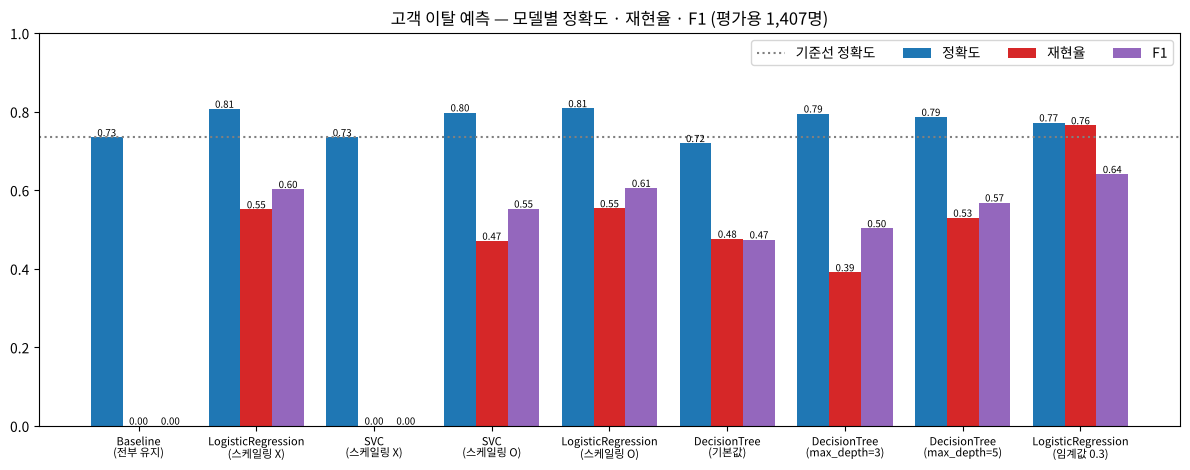

In [26]:
result_df = pd.DataFrame(results).T.round(4)
display(result_df)

# 비교 그림 (images/05_model_comparison.png)
plot_df = result_df[['정확도', '재현율', 'F1']]
fig, ax = plt.subplots(figsize=(12, 4.8))
xx = np.arange(len(plot_df)); w = 0.27
for j, (c, colr) in enumerate(zip(plot_df.columns, ['#1f77b4', '#d62728', '#9467bd'])):
    bars = ax.bar(xx + (j - 1) * w, plot_df[c], w, label=c, color=colr)
    ax.bar_label(bars, fmt='%.2f', fontsize=7)
ax.axhline(0.7342, color='gray', ls=':', label='기준선 정확도')
ax.set_xticks(xx); ax.set_xticklabels([n.replace(' (', '\n(') for n in plot_df.index], fontsize=8)
ax.set_ylim(0, 1); ax.legend(ncol=4, loc='upper right'); ax.set_title('고객 이탈 예측 — 모델별 정확도 · 재현율 · F1 (평가용 1,407명)')
plt.tight_layout(); plt.savefig('./images/05_model_comparison.png', dpi=110); plt.show()

## 12. 정리 ✅

| 모델 | 정확도 | 재현율 | 한 줄 |
|---|---|---|---|
| 기준선 (전부 유지) | 0.734 | 0 | 넘어야 할 최소 점수 |
| **LogisticRegression** (스케일링 O) | **0.808** | 0.554 | 오늘 1등. 단순하지만 강하다 |
| SVC (스케일링 X) | 0.734 | **0** | 전부 "유지" 예측 — 기준선과 같음 |
| SVC (스케일링 O) | 0.797 | 0.471 | 스케일링 하나로 +6%p |
| DecisionTree (기본값) | 0.719 | 0.476 | 학습용 0.998 — 외움, 기준선보다 낮음 |
| DecisionTree (`max_depth=3`) | 0.795 | 0.390 | 깊이 제한으로 +7.5%p |
| LogisticRegression (임계값 0.3) | 0.772 | **0.765** | 정확도 대신 이탈 고객을 더 많이 잡음 |

- **스케일링**: 거리 기반(SVM) · 경사 하강(로지스틱)은 필수, 트리는 불필요. `fit` 은 **학습용으로만**
- **과대적합**: 트리는 깊이 제한 없이 두면 학습 데이터를 외운다 → 학습용 / 평가용 정확도를 **같이** 본다
- **불균형 데이터**: 정확도가 기준선(0.734)보다 얼마나 높은지, 이탈 **재현율**이 얼마인지 확인
- 정확도 최고 = 좋은 모델이 아님 — 목적(이탈 방어)에 맞게 **임계값** · `class_weight='balanced'` 로 재현율을 조절

### 💬 필기의 모델 정리 — 고쳐서 다시

| 모델 | 분류 | 회귀 |
|---|---|---|
| 선형 회귀 · 다중 선형 회귀 | – | `LinearRegression` |
| 로지스틱 회귀 (이름은 회귀지만 **분류**) | `LogisticRegression` | – |
| SVM (양쪽) | `SVC` | `SVR` ← 회귀는 SVC 가 아니라 **SVR** |
| 결정 트리 (양쪽) | `DecisionTreeClassifier` | `DecisionTreeRegressor` |
| 랜덤 포레스트 (양쪽) | `RandomForestClassifier` | `RandomForestRegressor` |
| 앙상블: 배깅 · 부스팅 · 스태킹 | `XGBClassifier` · `StackingClassifier` | `XGBRegressor` · `StackingRegressor` |